# 20장 도메인 문서 분류 파이프라인

책의 마지막 장이다. 지금까지 NSMC와 YNAT으로 익힌 방법을 처음 보는 도메인 데이터에 처음부터 끝까지 적용한다. 데이터는 판례이고 과제는 판시사항을 읽고 법 분야 9개 가운데 하나를 고르는 일이다. NSMC·YNAT보다 문서가 길고 클래스가 많으며, 분야 사이의 경계가 현업 분류 체계처럼 규칙으로 정해진다.

- 20.1 문제 정의와 판례 데이터
- 20.2 라벨 스키마 설계
- 20.3 콜드 스타트와 초기 라벨 확보
- 20.4 Jev 능동 학습 루프 적용
- 20.5 사람 검수 작업 흐름
- 20.6 배포와 지속적 능동 학습
- 20.7 결과와 한계

학생 모델은 1부와 같은 TF-IDF·로지스틱 회귀이고 CPU로 돈다. 사람 라벨은 데이터의 정답 라벨로 시뮬레이션하고, 단가는 00_기획안 4.2절의 20장 가정값(건당 150원, 30초, 검수는 60%)을 쓴다. Jev 호출에 필요한 키·주소·모델 이름은 `jupyter/.env` 에서만 읽는다.

## 20.1 문제 정의와 판례 데이터

국가법령정보센터가 공개한 판례 데이터의 2차 배포본(Hugging Face `joonhok-exo-ai/korean_law_open_data_precedents`)을 쓴다. 다섯 개 parquet 파일을 `data/raw_prec/` 에 받아 둔다.

```bash
mkdir -p data/raw_prec && cd data/raw_prec
for i in 0 1 2 3 4; do curl -sLO "https://huggingface.co/datasets/joonhok-exo-ai/korean_law_open_data_precedents/resolve/main/data/train-0000$i-of-00005.parquet"; done
```

입력은 판시사항(판결이 판단한 쟁점의 요약)의 앞 300자다. 라벨은 참조조문에 처음 나오는 법률을 아래 규칙표로 9개 분야에 묶어 정한다. 규칙표에 없는 법률을 처음 인용한 판례는 뺀다. 선고 연도로 앞 구간(~2008)과 뒤 구간(2009~)을 나누고, 뒤 구간은 20.6절의 배포 후 스트림으로 남긴다.

In [1]:
# ── 판례 데이터 가공 ────
import glob, json, os
import numpy as np
import pandas as pd
FIELD = {
    "민사": ["민법", "주택임대차보호법", "자동차손해배상보장법", "가등기담보등에관한법", "이자제한법", "상가건물임대차보호법",
             "집합건물의소유및관리에관한법", "신원보증법", "제조물책임법", "약관의규제에관한법"],
    "민사절차": ["민사소송법", "민사집행법", "부동산등기법", "민사조정법", "소송촉진등에관한특례법", "채무자회생및파산에관한법",
                 "파산법", "회사정리법", "화의법", "비송사건절차법", "가사소송법", "경매법", "소액사건심판법"],
    "상사": ["상법", "어음법", "수표법", "보험업법", "증권거래법", "자본시장과금융투자업에관한법", "은행법", "신탁법"],
    "형사": ["형법", "특정범죄가중처벌등에관한법", "특정경제범죄가중처벌등에관한법", "폭력행위등처벌에관한법", "도로교통법",
             "교통사고처리특례법", "마약류관리에관한법", "성폭력범죄의처벌등에관한특례법", "국가보안법", "사회보호법", "공직선거법",
             "정보통신망이용촉진및정보보호등에관한법", "아동ㆍ청소년의성보호에관한법", "아동·청소년의성보호에관한법", "부정수표단속법",
             "총포ㆍ도검ㆍ화약류등단속법", "관세법", "공직선거및선거부정방지법", "군형법", "반공법", "조세범처벌법", "변호사법"],
    "형사절차": ["형사소송법", "형사보상법", "소년법"],
    "행정": ["행정소송법", "국가배상법", "행정심판법", "행정절차법", "지방자치법", "국가공무원법", "지방공무원법", "토지수용법",
             "공익사업을위한토지등의취득및보상에관한법", "건축법", "도시계획법", "국토의계획및이용에관한법", "사립학교법",
             "자동차운수사업법", "여객자동차운수사업법", "의료법", "약사법", "식품위생법", "도시및주거환경정비법", "농지개혁법",
             "귀속재산처리법", "병역법", "출입국관리법", "공무원연금법", "하천법", "도로법", "산림법", "광업법", "주택법",
             "택지개발촉진법", "국유재산법", "토지구획정리사업법", "공공용지의취득및손실보상에관한특례법", "국토이용관리법",
             "주택건설촉진법", "행정대집행법", "택지소유상한에관한법"],
    "조세": ["소득세법", "지방세법", "국세기본법", "부가가치세법", "법인세법", "상속세법", "상속세및증여세법", "국세징수법",
             "조세특례제한법", "조세감면규제법", "토지초과이득세법", "자산재평가법", "방위세법", "영업세법", "증권거래세법", "인지세법"],
    "노동": ["근로기준법", "산업재해보상보험법", "노동조합및노동관계조정법", "노동조합법", "노동쟁의조정법", "근로자퇴직급여보장법",
             "남녀고용평등법", "고용보험법", "파견근로자보호등에관한법", "최저임금법", "노동위원회법"],
    "지식재산": ["상표법", "특허법", "저작권법", "실용신안법", "의장법", "디자인보호법", "부정경쟁방지및영업비밀보호에관한법",
                 "부정경쟁방지법", "컴퓨터프로그램보호법"]}
FIELDS = list(FIELD)
L2F = {law: f for f, laws in FIELD.items() for law in laws}

raw = pd.concat([pd.read_parquet(f, columns=["판례정보일련번호", "사건종류명", "선고일자", "판시사항", "참조조문"])
                 for f in sorted(glob.glob("data/raw_prec/*.parquet"))])
d0 = raw[raw["판시사항"].fillna("").str.len() > 20].copy()
# 참조조문에 처음 나오는 법률 이름. 시행령·시행규칙은 모법으로 돌린다
law = d0["참조조문"].fillna("").str.extract(r"^\s*(?:\[\d+\])?\s*([가-힣·ㆍ]+?(?:법|령|규칙))")[0].fillna("")
d0["law"] = law.str.replace(r"(시행령|시행규칙|법시행령|법시행규칙)$", "", regex=True).str.replace(r"(법)?$", "법", regex=True).str.replace("법법", "법")
d0["field"], d0["yr"] = d0["law"].map(L2F), d0["선고일자"] // 10000
d0 = d0[d0["field"].notna() & d0["yr"].between(1950, 2025)].copy()
d0["text"] = (d0["판시사항"].str.replace(r"\[\d+\]\s*", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip().str[:300])
d0 = d0.drop_duplicates("text")
d0["label"] = d0["field"].map({f: i for i, f in enumerate(FIELDS)})
d0 = d0.rename(columns={"사건종류명": "kind", "판례정보일련번호": "id"})[["id", "text", "label", "yr", "kind"]].astype({"yr": int})

# 선고 연도로 나눈다. 앞 구간(~2008)은 풀·검증·시험, 뒤 구간(2009~)은 배포 후 스트림과 뒤 구간 시험
early = d0[d0.yr <= 2008].sample(frac=1, random_state=0)
late = d0[d0.yr >= 2009].sample(frac=1, random_state=0)
SPLIT = {"pool": early[:10000], "val": early[10000:11000], "test": early[11000:13000],
         "stream": late[:6000], "test_late": late[6000:8000]}
for k, v in SPLIT.items():
    v.to_csv(f"data/prec_{k}.csv", index=False)
json.dump(FIELDS, open("data/prec_labels.json", "w"), ensure_ascii=False)

print(f"원본 {len(raw):,} | 판시사항 있음 {(raw['판시사항'].fillna('').str.len() > 20).sum():,} | 분야 매핑·중복 제거 후 {len(d0):,}")
print(pd.DataFrame({k: [len(v), v.yr.min(), v.yr.max()] for k, v in SPLIT.items()}, index=["건수", "첫 해", "끝 해"]).to_string())

원본 171,599 | 판시사항 있음 71,636 | 분야 매핑·중복 제거 후 45,780
      pool   val  test  stream  test_late
건수   10000  1000  2000    6000       2000
첫 해   1950  1952  1953    2009       2009
끝 해   2008  2008  2008    2025       2025


분야 분포를 풀과 스트림에서 비교하고, 라벨 규칙이 판결의 성격과 얼마나 맞는지 사건종류명으로 대략 본다. 사건종류명은 민사·형사·일반행정·세무·특허·가사 여섯 가지다.

In [2]:
# ── 분야 분포와 라벨 노이즈 대리 지표 ────
dist = pd.DataFrame({k: np.bincount(SPLIT[k].label, minlength=9) / len(SPLIT[k]) for k in ("pool", "stream")}, index=FIELDS)
print((dist * 100).round(1).to_string())
# 사건종류명과 분야가 어긋나지 않는 비율. 분야 규칙이 판결의 성격과 얼마나 맞는지 본다
KIND = {"민사": ["민사"], "민사절차": ["민사"], "상사": ["민사"], "형사": ["형사"], "형사절차": ["형사"], "행정": ["일반행정"],
        "조세": ["세무", "일반행정"], "노동": ["민사", "일반행정"], "지식재산": ["특허", "민사"]}
fit = np.array([k in KIND[FIELDS[y]] for k, y in zip(d0.kind, d0.label)])
print(f"\n사건종류명과 분야가 맞는 비율 {fit.mean():.3f}")
print(f"판시사항 글자 수(300자 자른 뒤) 중앙값 {d0.text.str.len().median():.0f}, 평균 {SPLIT['pool'].text.str.len().mean():.1f}")

      pool  stream
민사    29.5    35.2
민사절차  13.1    12.4
상사     4.0     5.6
형사    16.6    17.5
형사절차   5.2     5.8
행정    14.2     9.2
조세     8.9     2.6
노동     3.7     5.4
지식재산   4.7     6.2

사건종류명과 분야가 맞는 비율 0.891
판시사항 글자 수(300자 자른 뒤) 중앙값 94, 평균 102.1


### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [3]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("prec",)}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

prec 풀 (10000, 50000) 시험 (2000, 50000) 클래스 9


3장의 엔트로피 점수를 다시 싣는다.

In [4]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

query_entropy = make_score_query(score_entropy)

In [5]:
# ── 검증·스트림·뒤 구간 시험 집합 ────
d = DATA["prec"]
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, max_features=50000, sublinear_tf=True)
vec.fit(pd.read_csv("data/prec_pool.csv").text)                                        # load_data와 같은 설정
val = pd.read_csv("data/prec_val.csv")
stream = pd.read_csv("data/prec_stream.csv").sort_values(["yr", "id"]).reset_index(drop=True)   # 선고 순서대로 들어온다
late_test = pd.read_csv("data/prec_test_late.csv")
d.update(val_texts=val.text.values, X_val=vec.transform(val.text), y_val=val.label.values,
         s_texts=stream.text.values, X_s=vec.transform(stream.text), y_s=stream.label.values, yr_s=stream.yr.values,
         X_late=vec.transform(late_test.text), y_late=late_test.label.values)
print(f"검증 {len(val)} | 스트림 {len(stream)} ({stream.yr.min()}~{stream.yr.max()}) | 뒤 구간 시험 {len(late_test)}")

검증 1000 | 스트림 6000 (2009~2025) | 뒤 구간 시험 2000


Jev 호출 함수는 4부와 같다.

In [6]:
# ── Jev 호출 함수 ────
import os
import requests
from dotenv import load_dotenv
from concurrent.futures import ThreadPoolExecutor

load_dotenv(".env")                      # jupyter/.env — 키·주소·모델 이름은 여기에만 있다
print({n: bool(os.getenv(n)) for n in ("JEV_API_KEY", "JEV_BASE_URL", "JEV_MODEL")})   # 값은 출력하지 않는다

JEV = dict(key=os.environ["JEV_API_KEY"], url=os.environ["JEV_BASE_URL"].rstrip("/"), model=os.environ["JEV_MODEL"])
MAX_CONC = 5                             # 동시 호출 수
SESSION = requests.Session()

def mask(text):
    # 오류 메시지에 키·주소·모델 이름이 섞여 나오지 않도록 가린다
    for v in JEV.values():
        text = text.replace(v, "***")
    return text

def jev_ask(state, questions):
    # 판정 질문 묶음을 한 번 보내고 (질문 이름별 답, 입력 토큰, 출력 토큰)을 돌려준다
    body = dict(model=JEV["model"], state=state, questions=questions)
    for wait in (2, 4, 8, 16, 32, 64, 120, 240, 480, 600):   # 일시 오류·연결 끊김은 쉬었다 다시 보낸다(최대 약 26분)
        try:
            r = SESSION.post(f"{JEV['url']}/v1/systemone", headers={"Authorization": f"Bearer {JEV['key']}"},
                             json=body, timeout=300)
        except requests.ConnectionError:                    # 오래 도는 실험에서 연결이 끊기면 잠시 쉬고 다시 보낸다
            time.sleep(wait)
            continue
        if r.status_code == 200:
            j = r.json()
            return j["answers"], j["usage"]["input_tokens"], j["usage"]["output_tokens"]
        time.sleep(wait)
    raise RuntimeError(mask(f"Jev 응답 {r.status_code}: {r.text[:300]}"))

{'JEV_API_KEY': True, 'JEV_BASE_URL': True, 'JEV_MODEL': True}


## 20.2 라벨 스키마 설계

13장처럼 스키마를 두 단계로 쓴다. S0은 분야 이름만 준다. S1은 분야마다 한 줄 설명을 달고, 라벨 규칙(참조조문의 첫 법률)이 가르는 경계를 문장으로 적는다. 민사와 민사절차, 형사와 형사절차, 행정과 조세·노동처럼 같은 소송에서 갈리는 쌍이 대상이다.

In [7]:
# ── 라벨 체계와 요청 만들기 ────
CHUNK = 50                                # 요청 하나에 넣는 문서 수
LABEL_NAMES = {"prec": FIELDS}
LABEL_DESC = {"prec": {
    "민사": "계약·소유권·손해배상·임대차·상속처럼 개인 사이의 권리와 의무",
    "민사절차": "민사 소송의 요건과 절차, 판결의 효력, 강제집행·가압류, 등기, 도산 절차",
    "상사": "회사·주식·상행위·어음·수표·보험·증권",
    "형사": "범죄가 되는지와 형벌",
    "형사절차": "수사·공소 제기·증거능력·공판·상소 같은 형사 재판 절차",
    "행정": "행정처분·행정소송·국가배상·공무원·토지수용·인허가",
    "조세": "국세·지방세의 부과·징수·환급",
    "노동": "근로관계·임금·퇴직금·해고·노동조합·산업재해 보상",
    "지식재산": "상표·특허·실용신안·디자인·저작권·부정경쟁"}}
TASK_SENT = {"prec": "판례의 판시사항을 읽고, 판결이 주로 적용한 법률의 분야를 고른다."}
RULES = {"prec": [
    "권리 자체가 쟁점이면 민사다. 당사자 적격·소의 이익·판결의 효력·강제집행·등기 절차가 쟁점이면 민사절차다",
    "죄가 되는지와 형량이 쟁점이면 형사다. 증거능력·공소 제기·상소·공판 절차가 쟁점이면 형사절차다",
    "세금의 부과·환급·면제가 쟁점이면 행정소송이라도 조세다",
    "임금·퇴직금·해고·산업재해 보상이 쟁점이면 민사 소송이나 행정소송이라도 노동이다",
    "상표·특허 등록을 둘러싼 심판과 소송은 지식재산이다",
    "회사의 기관·주식·주주총회, 어음, 보험 계약이 쟁점이면 상사다"]}

def schema_text(name, level):
    # level 0: 분야 이름만(S0), 1: 분야 설명 + 경계 규칙(S1)
    lines = [f"과제: {TASK_SENT[name]}", "분야:"]
    lines += [f"- {n}: {LABEL_DESC[name][n]}" if level else f"- {n}" for n in LABEL_NAMES[name]]
    lines += ["경계 규칙:"] + [f"- {r}" for r in RULES[name]] if level else []
    return "\n".join(lines)

def build_request(name, texts, schema=1, shots=()):
    # state = 스키마 → 퓨샷 예시 → 분류할 문서. 질문은 문서마다 label_i 하나
    parts = [schema_text(name, schema)]
    parts += ["예시:\n" + "\n".join(f'- "{t}" → {y}' for t, y in shots)] if len(shots) else []
    state = "\n\n".join(parts + ["분류할 판시사항:\n" + "\n".join(f"[{i}] {t}" for i, t in enumerate(texts))])
    qs = {f"label_{i}": {"type": "choice", "instructions": f"[{i}]번 판시사항의 법 분야",
                         "criteria": {n: None for n in LABEL_NAMES[name]}} for i in range(len(texts))}
    return state, qs

def jev_label(name, texts, cfg):
    # texts를 50개씩 묶어 판정한다. (선택지 확률 행렬, 묶음별 사용량)
    names = LABEL_NAMES[name]
    def one(s):
        state, qs = build_request(name, texts[s:s + CHUNK], **cfg)
        t0 = time.perf_counter()
        ans, a, b = jev_ask(state, qs)
        P = [[ans[f"label_{i}"]["probabilities"].get(m, 0.0) for m in names] for i in range(len(qs))]
        return P, dict(n_in=a, n_out=b, t=time.perf_counter() - t0, n=len(qs))
    with ThreadPoolExecutor(MAX_CONC) as ex:
        out = list(ex.map(one, range(0, len(texts), CHUNK)))
    P = np.array([p for o in out for p in o[0]])
    return P / P.sum(1, keepdims=True), pd.DataFrame([o[1] for o in out])

In [8]:
# ── Jev 판정 저장소 ────
# 열쇠는 문서 출처와 번호다: p(풀), v(검증), s(스트림). 같은 설정의 판정은 한 번만 받는다
os.makedirs("results/ch20_parts", exist_ok=True)

def load_cache(tag):
    path = f"results/ch20_parts/jev_{tag}.csv"
    df = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=["key", "n_in"])
    return {k: (p, t) for k, p, t in zip(df.key, df.filter(regex=r"^p\d").values.astype(float), df.n_in)}

def save_cache(tag, cache):
    rows = [dict(key=k, n_in=t, **{f"p{j}": x for j, x in enumerate(p)}) for k, (p, t) in cache.items()]
    pd.DataFrame(rows).to_csv(f"results/ch20_parts/jev_{tag}.csv", index=False)

def jev_lookup(keys, texts, cache, cfg):
    # 저장소에 없는 문서만 묻는다. (확률 행렬, 이 판정들의 토큰 몫 합, 이번에 새로 쓴 토큰)
    miss = [i for i, k in enumerate(keys) if k not in cache]
    new = 0.0
    if miss:
        P, u = jev_label("prec", np.asarray(texts)[miss], cfg)
        cache.update({keys[i]: (p, t) for i, p, t in zip(miss, P, np.repeat(u.n_in.values / u.n.values, u.n.values))})
        new = u.n_in.sum()
    return np.array([cache[k][0] for k in keys]), sum(cache[k][1] for k in keys), new

def pick_bal(y, idx0, n, rng):
    # 초기 라벨에서 분야마다 n개씩 예시를 고른다. 초기 라벨에 적게 든 분야는 있는 만큼만 고른다
    return rng.permutation(np.concatenate([rng.choice(idx0[y[idx0] == c], min(n, (y[idx0] == c).sum()), replace=False)
                                           for c in range(len(FIELDS))]))

def shots_of(d, idx0, seed, n=1):
    pick = pick_bal(d["y_pool"], idx0, n, np.random.default_rng(seed))
    return [(d["texts"][i], FIELDS[d["y_pool"][i]]) for i in pick]

검증 집합 앞 200개로 세 설정을 비교한다. 예시는 시드 0 루프의 초기 라벨 100개에서 분야마다 하나씩 고른다.

In [9]:
# ── 제로샷 스키마 점검 (표 20.1) ────
N_CHECK = 200
idx0 = np.random.default_rng(0).choice(d["X_pool"].shape[0], N_INIT, replace=False)     # 시드 0 루프의 무작위 초기 100개
CFGS = {"S0 제로샷": dict(schema=0), "S1 제로샷": dict(schema=1), "S1 + 예시 9개": dict(schema=1, shots=shots_of(d, idx0, 0))}
keys, texts, y_chk = [f"v{i}" for i in range(N_CHECK)], d["val_texts"][:N_CHECK], d["y_val"][:N_CHECK]
rows, PV = [], {}
for tag, cfg in CFGS.items():
    cache = load_cache("schema_" + tag.split()[0] + ("_shot" if "shots" in cfg else ""))
    n0 = len(cache)
    PV[tag], tok, new = jev_lookup(keys, texts, cache, cfg)
    save_cache("schema_" + tag.split()[0] + ("_shot" if "shots" in cfg else ""), cache)
    yp = PV[tag].argmax(1)
    rows.append(dict(config=tag, acc=accuracy_score(y_chk, yp), f1=f1_score(y_chk, yp, average="macro"),
                     tok_per_doc=tok / N_CHECK, new_tok=new))
tab_schema = pd.DataFrame(rows).set_index("config")
print(tab_schema.round(4).to_string())

              acc      f1  tok_per_doc  new_tok
config                                         
S0 제로샷      0.785  0.7794      186.025    37205
S1 제로샷      0.805  0.7927      195.185    39037
S1 + 예시 9개  0.810  0.8001      208.965    41793


In [10]:
# ── 혼동이 잦은 분야 쌍 ────
from sklearn.metrics import confusion_matrix
for tag in ("S0 제로샷", "S1 제로샷"):
    cm = confusion_matrix(y_chk, PV[tag].argmax(1), labels=range(9))
    pairs = sorted(((cm[i, j], FIELDS[i], FIELDS[j]) for i in range(9) for j in range(9) if i != j), reverse=True)[:5]
    print(f"{tag}: " + ", ".join(f"{a}→{b} {n}" for n, a, b in pairs))
BEST = tab_schema.f1.idxmax()
print(f"\n루프에 쓸 설정: {BEST}")
cm = pd.DataFrame(confusion_matrix(y_chk, PV[BEST].argmax(1), labels=range(9)), index=FIELDS, columns=FIELDS)
print(cm.to_string())

S0 제로샷: 민사절차→민사 6, 민사→민사절차 5, 형사→형사절차 4, 민사절차→형사절차 4, 형사절차→형사 2
S1 제로샷: 형사→형사절차 5, 민사절차→형사절차 5, 민사→민사절차 5, 형사절차→형사 2, 형사절차→민사절차 2

루프에 쓸 설정: S1 + 예시 9개
      민사  민사절차  상사  형사  형사절차  행정  조세  노동  지식재산
민사    37     5   2   0     0   0   0   2     0
민사절차   1    20   1   0     5   0   0   0     1
상사     1     0   8   0     0   0   0   0     0
형사     1     0   0  33     4   2   0   1     0
형사절차   0     1   0   2     8   0   0   0     0
행정     1     1   0   2     0  26   0   0     0
조세     1     0   0   0     0   1  14   0     0
노동     0     0   0   1     0   0   0   9     0
지식재산   0     0   0   1     1   0   0   0     7


## 20.3 콜드 스타트와 초기 라벨 확보

초기 라벨 100개를 어떻게 고르느냐에 따라 첫 모델과 퓨샷 예시가 달라진다. 무작위 100개와 8장의 클러스터 대표 100개를 비교한다. 클러스터 대표는 TF-IDF를 100차원으로 줄인 공간에서 k-평균으로 100개 클러스터를 만들고, 클러스터마다 중심에 가장 가까운 문서를 고른다. 비교는 사람 라벨만 쓰고 Jev는 부르지 않는다.

In [11]:
# ── 초기 라벨 고르기: 무작위와 클러스터 대표 ────
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

Z = normalize(TruncatedSVD(100, random_state=0).fit_transform(d["X_pool"]))

def init_random(d, seed, rng):
    return rng.choice(d["X_pool"].shape[0], N_INIT, replace=False)

def init_cluster(d, seed, rng):
    # 8장의 대표성: 100개 클러스터마다 중심에 가장 가까운 문서
    km = KMeans(N_INIT, n_init=1, random_state=seed).fit(Z)
    dist = ((Z - km.cluster_centers_[km.labels_]) ** 2).sum(1)
    return np.array([np.where(km.labels_ == c)[0][np.argmin(dist[km.labels_ == c])] for c in range(N_INIT)])

INITS = {"무작위": init_random, "클러스터 대표": init_cluster}
for name, fn in INITS.items():
    cov = [np.bincount(d["y_pool"][fn(d, s, np.random.default_rng(s))], minlength=9) for s in SEEDS]
    print(f"{name}: 분야 수 평균 {np.mean([(c > 0).sum() for c in cov]):.1f} | 가장 적은 분야의 문서 수 평균 "
          f"{np.mean([c.min() for c in cov]):.1f} | 시드 0 분포 {cov[0].tolist()}")

무작위: 분야 수 평균 8.8 | 가장 적은 분야의 문서 수 평균 2.0 | 시드 0 분포 [29, 9, 1, 14, 7, 16, 12, 4, 8]


클러스터 대표: 분야 수 평균 9.0 | 가장 적은 분야의 문서 수 평균 2.2 | 시드 0 분포 [30, 11, 2, 19, 7, 14, 8, 5, 4]


In [12]:
# ── 20장 루프 ────
UNIT, SEC, REVIEW = 150, 30, 0.6          # 00_기획안 4.2절 가정: 건당 150원, 30초, 검수는 단가·시간의 60%
R_REVIEW, M = 20, 150                     # 검수 비율(%), Jev 불일치 후보 수

def kl_div(PJ, P):
    return (PJ * (np.log(PJ + 1e-12) - np.log(P + 1e-12))).sum(1)

def query_jev_kl(model, X, idx_u, k, keys, texts, cache, cfg, memo):
    # 17장 Jev 불일치: 엔트로피 상위 M개를 Jev가 판정하고 KL 상위 k개를 고른다. 고른 문서의 판정을 memo에 남긴다
    P = proba(model, X[idx_u], 9)
    h = score_entropy(P)
    top = np.argsort(-h)[:M]
    cand = idx_u[top]
    PJ, tok, new = jev_lookup([keys(i) for i in cand], texts[cand], cache, cfg)
    sel = np.lexsort((-h[top], -kl_div(PJ, P[top])))[:k]
    memo.update(P={int(i): p for i, p in zip(cand[sel], PJ[sel])}, tok=tok, new=new)
    return cand[sel]

def route_conf(Pj, r):
    # 16장 기본값: 이번 배치의 Jev 라벨 가운데 신뢰도가 낮은 r%를 검수로 보낸다
    return np.argsort(Pj.max(1), kind="stable")[:round(len(Pj) * r / 100)]

def review_log(q, Pj, rev, y, rnd):
    # 검수 작업 흐름(20.5)을 보려고 Jev 라벨마다 1·2순위와 검수 여부를 남긴다
    o = np.argsort(-Pj, 1)
    return pd.DataFrame(dict(idx=q, round=rnd, jev=o[:, 0], p1=Pj[np.arange(len(q)), o[:, 0]], jev2=o[:, 1],
                             p2=Pj[np.arange(len(q)), o[:, 1]], gold=y[q], reviewed=np.isin(np.arange(len(q)), rev)))

# 칸 이름: (질의, 라벨 출처, 검수 비율)
ARMS = {"Random·사람": ("Random", "사람", 0), "엔트로피·사람": ("엔트로피", "사람", 0),
        "엔트로피·혼합": ("엔트로피", "Jev", R_REVIEW), "Jev 불일치·혼합": ("Jev 불일치", "재사용", R_REVIEW)}

def run_agent(d, seed, arm, cache, cfg, init, budget=BUDGET, k=K):
    qname, src, r = ARMS[arm]
    rng = np.random.default_rng(seed)
    y = d["y_pool"]
    idx_l = INITS[init](d, seed, rng)
    Q = np.eye(9)[y[idx_l]]                                                        # 초기 100개는 사람 라벨
    idx_u = np.setdiff1d(np.arange(len(y)), idx_l)
    log, revs, tok, tok_new, n_rev = [], [], 0.0, 0.0, 0
    key = lambda i: f"p{i}"
    while True:
        model = train_model(d["X_pool"][idx_l], Q.argmax(1), seed)                   # 1. train
        y_hat = model.predict(d["X_test"])
        log.append(dict(seed=seed, n_labeled=len(idx_l), f1=f1_score(d["y_test"], y_hat, average="macro"),
                        acc=accuracy_score(d["y_test"], y_hat), noise=(Q.argmax(1) != y[idx_l]).mean(),
                        reviews=n_rev, tok=tok, tok_new=tok_new))
        if len(idx_l) >= budget:
            break
        m, memo = min(k, budget - len(idx_l)), {}
        if qname == "Jev 불일치":                                                   # 2. predict · 3. query
            q = query_jev_kl(model, d["X_pool"], idx_u, m, key, d["texts"], cache, cfg, memo)
            tok, tok_new = tok + memo["tok"], tok_new + memo["new"]
        else:
            q = (query_random if qname == "Random" else query_entropy)(model, d, idx_l, None, idx_u, m, rng)
        if src == "사람":                                                           # 4. label
            Pj = np.eye(9)[y[q]]
        elif src == "재사용":
            Pj = np.array([memo["P"][int(i)] for i in q])
        else:
            Pj, a, b = jev_lookup([key(i) for i in q], d["texts"][q], cache, cfg)
            tok, tok_new = tok + a, tok_new + b
        rev = route_conf(Pj, r) if r else np.array([], int)
        if src != "사람":
            revs.append(review_log(q, Pj, rev, y, len(log)))
        Pj[rev] = np.eye(9)[y[q[rev]]]                                                # 4b. 사람 검수
        n_rev += len(rev)
        idx_l, Q = np.r_[idx_l, q], np.vstack([Q, Pj])                                # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l, Q, (pd.concat(revs) if revs else pd.DataFrame())

In [13]:
# ── 콜드 스타트 비교 (사람 라벨, Jev 없음) ────
def tagof(s):
    return s.replace(" ", "_").replace("·", "-")

def run_cold(init, arm, seed):
    path = f"results/ch20_parts/cold_{tagof(init)}_{tagof(arm)}_{seed}.csv"
    if not os.path.exists(path):
        df, *_ = run_agent(d, seed, arm, None, None, init)
        df.assign(init=init, arm=arm).to_csv(path, index=False)
    return pd.read_csv(path)

def alc_of(g):
    return [alc(x.n_labeled.values, x.f1.values) for _, x in g.groupby("seed")]

cold = pd.concat(Parallel(n_jobs=10)(delayed(run_cold)(i, a, s) for i in INITS for a in ("Random·사람", "엔트로피·사람") for s in SEEDS))
tab_cold = cold.groupby(["init", "arm"], sort=False).apply(lambda g: pd.Series(dict(
    ALC=np.mean(alc_of(g)), ALC_std=np.std(alc_of(g)), f1_100=g[g.n_labeled == N_INIT].f1.mean(),
    f1_500=g[g.n_labeled == 500].f1.mean(), final=g[g.n_labeled == BUDGET].f1.mean())), include_groups=False)
print(tab_cold.round(4).to_string())
INIT = tab_cold.xs("엔트로피·사람", level="arm").ALC.idxmax()
print(f"\n20.4절 루프의 초기 라벨: {INIT}")

                      ALC  ALC_std  f1_100  f1_500   final
init    arm                                               
무작위     Random·사람  0.5841   0.0088  0.1527  0.4742  0.7283
        엔트로피·사람    0.6891   0.0096  0.1527  0.6502  0.7882
클러스터 대표 Random·사람  0.5860   0.0091  0.1379  0.5050  0.7200
        엔트로피·사람    0.6903   0.0065  0.1379  0.6482  0.7907

20.4절 루프의 초기 라벨: 클러스터 대표


## 20.4 Jev 능동 학습 루프 적용

17·19장이 권장한 구성을 그대로 옮긴다. 기준선은 Random·사람과 엔트로피·사람이다. Jev 구성은 엔트로피·혼합(엔트로피 질의, Jev 라벨, 신뢰도 하위 20% 검수)과 Jev 불일치·혼합(엔트로피 상위 150개를 Jev가 판정하고 KL 상위 50개를 골라 그 판정을 라벨로 다시 쓰고, 신뢰도 하위 20% 검수)이다. Jev 설정은 20.2절의 최선 설정이고, 예시는 시드마다 그 시드의 초기 라벨에서 고른다.

먼저 시드 0의 초기 모델로 질의를 한 번 돌려 문서당 입력 토큰을 잰다.

In [14]:
# ── 첫 호출 점검 ────
SCHEMA_BEST = CFGS[BEST]
def seed_cfg(seed):
    # 그 시드의 초기 라벨에서 분야마다 한 개씩 예시를 고른다. 20.2절 최선 설정이 예시를 쓰지 않으면 스키마만 쓴다
    idx0 = INITS[INIT](d, seed, np.random.default_rng(seed))
    return dict(schema=SCHEMA_BEST["schema"], shots=shots_of(d, idx0, seed) if "shots" in SCHEMA_BEST else ())

cache, memo = load_cache("loop_0"), {}
idx0 = INITS[INIT](d, 0, np.random.default_rng(0))
model = train_model(d["X_pool"][idx0], d["y_pool"][idx0], 0)
n0, t0 = len(cache), time.perf_counter()
q = query_jev_kl(model, d["X_pool"], np.setdiff1d(np.arange(d["X_pool"].shape[0]), idx0), K, lambda i: f"p{i}",
                 d["texts"], cache, seed_cfg(0), memo)
save_cache("loop_0", cache)
print(f"새 판정 {len(cache) - n0}개 | 새 입력 토큰 {memo['new']:,.0f} (문서당 {memo['new'] / max(len(cache) - n0, 1):.1f}) | "
      f"{time.perf_counter() - t0:.1f}초 | 고른 {len(q)}개의 Jev 라벨 정확도 "
      f"{np.mean([memo['P'][int(i)].argmax() == d['y_pool'][i] for i in q]):.2f}")

새 판정 150개 | 새 입력 토큰 29,212 (문서당 194.7) | 0.7초 | 고른 50개의 Jev 라벨 정확도 1.00


시드 다섯 개를 CPU 코어에 나눠 동시에 돈다. 같은 시드의 칸들은 판정 저장소를 함께 쓴다.

In [15]:
# ── 전체 실행 ────
def run_job(seed):
    cache, cfg, out = load_cache(f"loop_{seed}"), seed_cfg(seed), []
    for arm in ARMS:
        path = f"results/ch20_parts/loop_{tagof(arm)}_{seed}.csv"
        if not os.path.exists(path):
            t0 = time.perf_counter()
            df, idx_l, Q, rv = run_agent(d, seed, arm, cache, cfg, INIT)
            np.savez(path.replace("loop_", "lab_").replace(".csv", ".npz"), idx=idx_l, Q=Q)
            rv.assign(arm=arm, seed=seed).to_csv(path.replace("loop_", "rev_"), index=False)
            df.assign(arm=arm, wall=time.perf_counter() - t0).to_csv(path, index=False)
            save_cache(f"loop_{seed}", cache)
        out.append(pd.read_csv(path))
    return pd.concat(out, ignore_index=True)

t0 = time.perf_counter()
res = pd.concat(Parallel(n_jobs=len(SEEDS))(delayed(run_job)(s) for s in SEEDS), ignore_index=True)
print(f"완료 {(time.perf_counter() - t0) / 60:.1f}분 | 루프가 새로 쓴 입력 토큰 {res[res.n_labeled == BUDGET].tok_new.sum():,.0f}")

완료 7.5분 | 루프가 새로 쓴 입력 토큰 2,963,197


(label_acc = 질의 라벨 1,900개 정확도, cost_h = 사람 비용(원), hours = 사람 작업 시간, tok = Jev 입력 토큰 몫)
               ALC  ALC_std   final  label_acc  reviews    cost_h    hours           tok
arm                                                                                     
Random·사람   0.5860   0.0102  0.7200     1.0000      0.0  300000.0  16.6667  0.000000e+00
엔트로피·사람     0.6903   0.0073  0.7907     1.0000      0.0  300000.0  16.6667  0.000000e+00
엔트로피·혼합     0.6795   0.0064  0.7511     0.8197    380.0   49200.0   2.7333  3.700761e+05
Jev 불일치·혼합  0.6903   0.0053  0.7592     0.8288    380.0   49200.0   2.7333  1.176572e+06


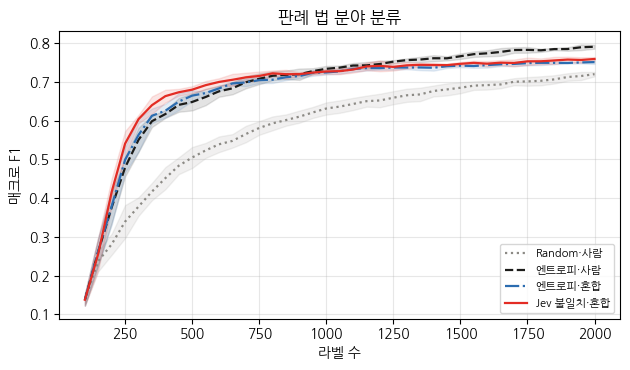

In [16]:
# ── 학습 곡선과 구성별 비교 (표 20.2) ────
human = np.where(res.arm.str.endswith("사람"), res.n_labeled, N_INIT)
res["cost_h"] = human * UNIT + REVIEW * res.reviews * UNIT
res["hours"] = (human * SEC + REVIEW * res.reviews * SEC) / 3600

STY = dict(zip(ARMS, [(GRAY2, ":"), (INK, "--"), ("#2B6CB0", "-."), (ACCENT, "-")]))
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for arm in ARMS:
    g = res[res.arm == arm].groupby("n_labeled").f1.agg(["mean", "std"])
    c, ls = STY[arm]
    ax.plot(g.index, g["mean"], color=c, ls=ls, lw=1.6, label=arm)
    ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"], color=c, alpha=0.12)
ax.set(xlabel="라벨 수", ylabel="매크로 F1", title="판례 법 분야 분류")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("out/ch20_curves.png", dpi=200)

last = res[res.n_labeled == BUDGET].groupby("arm", sort=False).agg(
    final=("f1", "mean"), noise=("noise", "mean"), reviews=("reviews", "mean"),
    cost_h=("cost_h", "mean"), hours=("hours", "mean"), tok=("tok", "mean"))
alcs = res.groupby(["arm", "seed"], sort=False).apply(lambda x: alc(x.n_labeled.values, x.f1.values), include_groups=False)
tab2 = last.join(alcs.groupby("arm", sort=False).agg(["mean", "std"]).rename(columns={"mean": "ALC", "std": "ALC_std"}))
tab2["label_acc"] = 1 - tab2.noise * BUDGET / (BUDGET - N_INIT)
print("(label_acc = 질의 라벨 1,900개 정확도, cost_h = 사람 비용(원), hours = 사람 작업 시간, tok = Jev 입력 토큰 몫)")
print(tab2[["ALC", "ALC_std", "final", "label_acc", "reviews", "cost_h", "hours", "tok"]].round(4).to_string())

## 20.5 사람 검수 작업 흐름

혼합 오라클에서 사람이 보는 것은 검수 큐다. 라운드마다 Jev 라벨 50개 가운데 신뢰도(1순위 확률)가 낮은 10개가 큐에 오른다. 큐에 어떤 분야가 몰리는지, 큐 안의 Jev 라벨이 얼마나 틀리는지, 틀렸을 때 정답이 2순위에 있는지를 본다. 2순위에 정답이 자주 있으면 검수 화면에 두 후보를 나란히 보여 주는 편이 빠르다.

In [17]:
# ── 검수 큐 ────
rv = pd.concat([pd.read_csv(f"results/ch20_parts/rev_{tagof(a)}_{s}.csv") for a in ("엔트로피·혼합", "Jev 불일치·혼합") for s in SEEDS])
rv["ok"] = rv.jev == rv.gold
print("검수 큐(신뢰도 하위 20%)와 나머지의 Jev 라벨 정확도, 1순위 확률 평균")
print(rv.groupby(["arm", "reviewed"]).agg(n=("ok", "size"), jev_acc=("ok", "mean"), p1=("p1", "mean")).round(4).to_string())
q = rv[rv.reviewed]
share = pd.DataFrame({"검수 큐 정답 분야": np.bincount(q.gold, minlength=9) / len(q),
                      "Jev 라벨 전체 정답 분야": np.bincount(rv.gold, minlength=9) / len(rv),
                      "검수 큐 안 Jev 오답률": [1 - q[q.gold == c].ok.mean() for c in range(9)]}, index=FIELDS)
print("\n" + (share * 100).round(1).to_string())
wrong = q[~q.ok]
print(f"\n검수 큐 오답 가운데 정답이 Jev 2순위인 비율 {(wrong.jev2 == wrong.gold).mean():.3f}")
pairs = wrong.groupby(["gold", "jev"]).size().sort_values(ascending=False).head(5)
print("검수 큐에서 잦은 오답 (정답 → Jev): " + ", ".join(f"{FIELDS[a]}→{FIELDS[b]} {n}" for (a, b), n in pairs.items()))
per_round = q.groupby(["arm", "seed", "round"]).size().groupby("arm").mean()
print(f"\n라운드당 검수 {per_round.round(1).to_dict()} 건 | 한 라운드 검수 시간 {per_round.mean() * SEC * REVIEW / 60:.1f}분")

검수 큐(신뢰도 하위 20%)와 나머지의 Jev 라벨 정확도, 1순위 확률 평균
                        n  jev_acc      p1
arm        reviewed                       
Jev 불일치·혼합 False     7600   0.7861  0.9146
           True      1900   0.5000  0.6406
엔트로피·혼합    False     7600   0.7746  0.8998
           True      1900   0.4689  0.5524

      검수 큐 정답 분야  Jev 라벨 전체 정답 분야  검수 큐 안 Jev 오답률
민사          20.7             20.8            60.3
민사절차        24.0             15.8            53.3
상사           5.2              6.2            38.9
형사          14.3             15.1            53.3
형사절차         8.1              7.1            38.5
행정          16.1             14.9            51.1
조세           6.9              9.4            55.9
노동           2.8              4.5            30.6
지식재산         1.8              6.2            29.4

검수 큐 오답 가운데 정답이 Jev 2순위인 비율 0.690
검수 큐에서 잦은 오답 (정답 → Jev): 민사절차→민사 126, 민사→상사 125, 민사→민사절차 119, 형사→형사절차 117, 민사절차→형사절차 113

라운드당 검수 {'Jev 불일치·혼합': 10.0, '엔트로피·혼합': 10.0} 건 | 한 라운드 검수 시간 3.0분


검수 화면에는 판시사항, Jev의 1·2순위 분야와 확률이 놓인다. Jev는 판정만 하므로 선택 근거 문장은 없다. 시드 0 Jev 불일치·혼합 칸에서 신뢰도가 가장 낮았던 세 건이다.

In [18]:
# ── 검수자가 보는 화면 ────
ex = rv[(rv.arm == "Jev 불일치·혼합") & (rv.seed == 0) & rv.reviewed].sort_values("p1").head(3)
for _, r in ex.iterrows():
    print(f"[라운드 {r['round']}] {d['texts'][r.idx][:110]}…")
    print(f"   Jev 1순위 {FIELDS[r.jev]} {r.p1:.2f} | 2순위 {FIELDS[r.jev2]} {r.p2:.2f} | 검수 결과 {FIELDS[r.gold]}\n")

[라운드 28] 수차에 걸쳐 원자재를 계속적으로 매입하였다고 하면서 공급자의 성명, 상호, 사업장 소재지를 모른다는 것이 경험칙에 반한다고 본 사례…
   Jev 1순위 조세 0.30 | 2순위 형사절차 0.28 | 검수 결과 민사절차

[라운드 33] 검사의 조사결과통보 지연과 징계사유의 시효…
   Jev 1순위 노동 0.35 | 2순위 형사절차 0.31 | 검수 결과 행정

[라운드 20] 법인이 ‘채권보전용’ 토지를 매각 유예기간 내에 매각을 포기한 경우, 유예기간 내에 매각되지 아니한 데 대한 ‘정당한 사유’가 있는지 여부(소극) 수산업 협동조합이 채권보전용 부동산을 유예기간 내에…
   Jev 1순위 민사절차 0.36 | 2순위 상사 0.33 | 검수 결과 조세



## 20.6 배포와 지속적 능동 학습

20.4절 Jev 불일치·혼합 칸이 라벨 2,000개로 학습한 모델을 2008년에 배포했다고 본다. 그 뒤 2009~2025년 판례 6,000건이 선고 순서대로 500건씩 열두 구간으로 들어온다. 세 가지 운영 방식을 비교한다.

| 방식 | 규칙 |
|---|---|
| 고정 | 배포한 모델을 그대로 둔다 |
| 주기 재학습 | 구간마다 그 구간에서 Jev 불일치로 50개를 골라 라벨을 붙이고(검수 20%) 재학습한다 |
| Jev 일치 감시 | 구간마다 50개를 Jev가 판정해 학생 예측과의 카파 κ_t를 잰다. κ_t가 배포 전 검증 집합에서 잰 기준 카파보다 0.05 넘게 낮으면 주기 재학습과 같은 방식으로 재학습한다 |

Jev 일치 감시는 17장의 Jev 일치 종료 조건을 거꾸로 쓴다. 17장은 일치가 더 오르지 않을 때 멈췄고, 여기서는 일치가 떨어질 때 다시 움직인다. 구간 성능은 재학습 전 모델이 그 구간을 얼마나 맞히는지(사전 순차 평가)이고, 뒤 구간 시험 집합 2,000개로 구간이 끝날 때의 모델도 잰다.

In [19]:
# ── 배포 후 스트림과 세 가지 운영 방식 ────
from sklearn.metrics import cohen_kappa_score
import scipy.sparse as sp
SEG, DEPLOY, DELTA, N_PROBE = 500, "Jev 불일치·혼합", 0.05, 50
POLICIES = ["고정", "주기 재학습", "Jev 일치 감시"]

def run_stream(seed, policy):
    lab = np.load(f"results/ch20_parts/lab_{tagof(DEPLOY)}_{seed}.npz")
    X_tr, y_tr = d["X_pool"][lab["idx"]], lab["Q"].argmax(1)                          # 20.4절 라벨 2,000개로 학습한 모델
    model = train_model(X_tr, y_tr, seed)
    cache, cfg, rng = load_cache(f"loop_{seed}"), seed_cfg(seed), np.random.default_rng(seed)
    # 기준 카파: 배포 전 검증 200개에서 학생 예측과 Jev 라벨의 일치
    PV0, _, new0 = jev_lookup([f"v{i}" for i in range(N_CHECK)], d["val_texts"][:N_CHECK], cache, cfg)
    k_ref = cohen_kappa_score(model.predict(d["X_val"][:N_CHECK]), PV0.argmax(1))
    log, n_lab, n_rev, tok, tok_new = [], 0, 0, 0.0, new0              # 기준 카파 판정의 새 토큰도 센다
    for t, s in enumerate(range(0, len(d["y_s"]), SEG)):
        seg = np.arange(s, s + SEG)
        y_seg = model.predict(d["X_s"][seg])
        row = dict(seed=seed, policy=policy, seg=t, yr=d["yr_s"][seg].mean(), f1_seg=f1_score(d["y_s"][seg], y_seg, average="macro"),
                   k_ref=k_ref, kappa=np.nan, update=False)
        go = policy == "주기 재학습"
        if policy == "Jev 일치 감시":                                               # 감시: 구간마다 50개를 Jev가 판정한다
            probe = rng.choice(seg, N_PROBE, replace=False)
            Pp, a, b = jev_lookup([f"s{i}" for i in probe], d["s_texts"][probe], cache, cfg)
            tok, tok_new = tok + a, tok_new + b
            row["kappa"] = cohen_kappa_score(y_seg[probe - s], Pp.argmax(1))
            go = row["kappa"] < k_ref - DELTA
        if go:                                                                        # 재학습: 그 구간에서 Jev 불일치로 50개를 고른다
            memo = {}
            q = query_jev_kl(model, d["X_s"], seg, K, lambda i: f"s{i}", d["s_texts"], cache, cfg, memo)
            Pj = np.array([memo["P"][int(i)] for i in q])
            rev = route_conf(Pj, R_REVIEW)
            yq = Pj.argmax(1)
            yq[rev] = d["y_s"][q[rev]]
            X_tr, y_tr = sp.vstack([X_tr, d["X_s"][q]]), np.r_[y_tr, yq]
            model = train_model(X_tr, y_tr, seed)
            n_lab, n_rev, tok, tok_new = n_lab + len(q), n_rev + len(rev), tok + memo["tok"], tok_new + memo["new"]
            row["update"] = True
        row.update(f1_late=f1_score(d["y_late"], model.predict(d["X_late"]), average="macro"),
                   f1_early=f1_score(d["y_test"], model.predict(d["X_test"]), average="macro"),
                   n_lab=n_lab, n_rev=n_rev, tok=tok, tok_new=tok_new)
        log.append(row)
    save_cache(f"loop_{seed}", cache)
    return pd.DataFrame(log)

def stream_job(seed):
    path = f"results/ch20_parts/stream_{seed}.csv"
    if not os.path.exists(path):
        pd.concat([run_stream(seed, p) for p in POLICIES]).to_csv(path, index=False)
    return pd.read_csv(path)

t0 = time.perf_counter()
st = pd.concat(Parallel(n_jobs=len(SEEDS))(delayed(stream_job)(s) for s in SEEDS), ignore_index=True)
print(f"완료 {(time.perf_counter() - t0) / 60:.1f}분 | 새로 쓴 입력 토큰 {st.groupby(['seed', 'policy']).tok_new.max().sum():,.0f}")

완료 1.4분 | 새로 쓴 입력 토큰 3,628,615


배포 시점 모델의 뒤 구간 시험 F1(고정 칸 첫 구간) 0.7832, 앞 구간 시험 F1 0.7592
           f1_seg  f1_late  f1_early  updates  n_lab  n_rev   cost_h          tok
policy                                                                           
고정         0.7841   0.7832    0.7592      0.0    0.0    0.0      0.0       0.0000
주기 재학습     0.8032   0.8155    0.7687     12.0  600.0  120.0  10800.0  532481.4000
Jev 일치 감시  0.7896   0.7906    0.7640      2.2  110.0   22.0   1980.0  287558.2798

기준 카파 평균 0.784 | 구간 카파 평균 0.789 | 구간별 재학습 시드 수 [1, 0, 2, 1, 1, 1, 0, 1, 1, 1, 0, 2]
구간 평균 선고 연도 [2009, 2010, 2011, 2012, 2013, 2014, 2016, 2018, 2020, 2021, 2023, 2024]


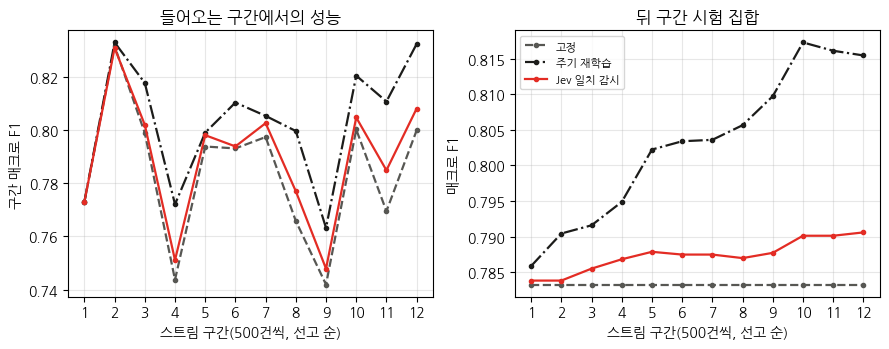

In [20]:
# ── 운영 방식 비교 (표 20.3, 그림 20.3) ────
st["cost_h"] = REVIEW * st.n_rev * UNIT              # 스트림 라벨은 Jev가 붙이고 검수만 사람이 한다
end = st[st.seg == st.seg.max()].groupby("policy", sort=False).agg(
    f1_late=("f1_late", "mean"), f1_early=("f1_early", "mean"), n_lab=("n_lab", "mean"), n_rev=("n_rev", "mean"),
    cost_h=("cost_h", "mean"), tok=("tok", "mean"))
end["updates"] = st.groupby("policy", sort=False).update.sum() / len(SEEDS)
end["f1_seg"] = st.groupby("policy", sort=False).f1_seg.mean()
print(f"배포 시점 모델의 뒤 구간 시험 F1(고정 칸 첫 구간) {st[(st.policy == '고정') & (st.seg == 0)].f1_late.mean():.4f}, "
      f"앞 구간 시험 F1 {st[(st.policy == '고정') & (st.seg == 0)].f1_early.mean():.4f}")
print(end[["f1_seg", "f1_late", "f1_early", "updates", "n_lab", "n_rev", "cost_h", "tok"]].round(4).to_string())
mon = st[st.policy == "Jev 일치 감시"]
print(f"\n기준 카파 평균 {mon.k_ref.mean():.3f} | 구간 카파 평균 {mon.kappa.mean():.3f} | 구간별 재학습 시드 수 "
      f"{mon.groupby('seg').update.sum().astype(int).tolist()}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for pol, (c, ls) in zip(POLICIES, [(GRAY, "--"), (INK, "-."), (ACCENT, "-")]):
    g = st[st.policy == pol].groupby("seg")[["f1_seg", "f1_late"]].mean()
    axes[0].plot(g.index + 1, g.f1_seg, color=c, ls=ls, lw=1.6, marker="o", ms=3, label=pol)
    axes[1].plot(g.index + 1, g.f1_late, color=c, ls=ls, lw=1.6, marker="o", ms=3, label=pol)
yrs = st[st.policy == "고정"].groupby("seg").yr.mean()
axes[0].set(xlabel="스트림 구간(500건씩, 선고 순)", ylabel="구간 매크로 F1", title="들어오는 구간에서의 성능")
axes[1].set(xlabel="스트림 구간(500건씩, 선고 순)", ylabel="매크로 F1", title="뒤 구간 시험 집합")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_xticks(range(1, len(yrs) + 1))
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig("out/ch20_continual.png", dpi=200)
print("구간 평균 선고 연도", yrs.round(0).astype(int).tolist())

재학습이 도운 것이 뒤 구간의 라벨이어서인지, 그저 라벨이 600개 늘어서인지 가르려고 20.4절 곡선에서 앞 구간 풀 라벨 600개가 더해졌을 때의 상승과 견준다. 시험 집합이 달라 엄밀한 통제 실험은 아니다. 감시 카파가 구간마다 얼마나 흔들리는지도 문턱 δ와 견준다.

In [20]:
# ── 추가 라벨의 출처와 감시 신호의 흔들림 ────
dep = res[res.arm == DEPLOY].groupby("n_labeled").f1.mean()
fx = st[st.policy == "고정"].groupby("seed").f1_late.last().mean()
pr = st[st.policy == "주기 재학습"].groupby("seed").f1_late.last().mean()
print(f"앞 구간 풀 라벨 600개 더(20.4절 {DEPLOY}, 1,400 → 2,000): 앞 구간 시험 F1 {dep.loc[1400]:.4f} → {dep.loc[BUDGET]:.4f} "
      f"(+{dep.loc[BUDGET] - dep.loc[1400]:.4f})")
print(f"뒤 구간 스트림 라벨 600개 더(주기 재학습): 뒤 구간 시험 F1 {fx:.4f} → {pr:.4f} (+{pr - fx:.4f})")
mon = st[st.policy == "Jev 일치 감시"]
print(f"감시 카파: 구간·시드 전체 표준편차 {mon.kappa.std():.3f} | 시드별 기준 카파 {mon.groupby('seed').k_ref.first().round(3).tolist()} | "
      f"문턱 δ = {DELTA}")

앞 구간 풀 라벨 600개 더(20.4절 Jev 불일치·혼합, 1,400 → 2,000): 앞 구간 시험 F1 0.7438 → 0.7592 (+0.0154)
뒤 구간 스트림 라벨 600개 더(주기 재학습): 뒤 구간 시험 F1 0.7832 → 0.8155 (+0.0322)
감시 카파: 구간·시드 전체 표준편차 0.075 | 시드별 기준 카파 [0.811, 0.771, 0.793, 0.788, 0.759] | 문턱 δ = 0.05


## 20.7 결과와 한계

이 장이 쓴 Jev 입력 토큰을 정리한다. 결과의 해석과 한계는 원고에서 다룬다.

In [21]:
# ── 이 장이 쓴 Jev 입력 토큰 ────
tok_schema = tab_schema.new_tok.sum()
tok_loop = res[res.n_labeled == BUDGET].tok_new.sum()
tok_stream = st.groupby(["seed", "policy"]).tok_new.max().sum()
print(f"스키마 점검 {tok_schema:,.0f} | 루프 {tok_loop:,.0f} | 스트림 {tok_stream:,.0f} | 합계 {tok_schema + tok_loop + tok_stream:,.0f}")
print("(첫 호출 점검의 판정은 시드 0 루프 저장소에 들어가 루프 몫에 포함되지 않는다)")

스키마 점검 118,035 | 루프 2,963,197 | 스트림 3,628,615 | 합계 6,709,847
(첫 호출 점검의 판정은 시드 0 루프 저장소에 들어가 루프 몫에 포함되지 않는다)
